In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

ImportError: DLL load failed while importing ormsgpack: An Application Control policy has blocked this file.

In [14]:
class CricketStatsState(TypedDict):
    runs: int
    balls: int
    sixes: int
    fours: int
    
    strike_rate: float
    balls_per_boundary: float
    boundary_percentage: float

    summary: str

In [ ]:
def calculate_strike_rate(state: CricketStatsState):
    runs = state.get("runs", 0)
    balls = state.get("balls", 1)  # Avoid division by zero
    strike_rate = (runs / balls) * 100
    return {"strike_rate": strike_rate} # partial updates to prevent usage error for passed state.

def calculate_balls_per_boundary(state: CricketStatsState):
    balls = state.get("balls", 1)  # Avoid division by zero
    total_boundaries = state.get("sixes", 0) + state.get("fours", 0)
    balls_per_boundary = balls / total_boundaries if total_boundaries > 0 else float('inf')
    return {**state, "balls_per_boundary": balls_per_boundary}

def calculate_boundary_percentage(state: CricketStatsState):
    total_boundaries = state.get("sixes", 0) + state.get("fours", 0)
    balls = state.get("balls", 1)  # Avoid division by zero
    boundary_percentage = (total_boundaries / balls) * 100 if balls > 0 else 0
    return {"boundary_percentage": boundary_percentage}

def summary(state: CricketStatsState) -> CricketStatsState:
    runs = state.get("runs", 0)
    balls = state.get("balls", 0)
    sixes = state.get("sixes", 0)
    fours = state.get("fours", 0)
    strike_rate = state.get("strike_rate", 0.0)
    balls_per_boundary = state.get("balls_per_boundary", float('inf'))
    boundary_percentage = state.get("boundary_percentage", 0.0)

    summary_text = (
        f"Player scored {runs} runs off {balls} balls, hitting {sixes} sixes and {fours} fours. "
        f"Strike Rate: {strike_rate:.2f}, Balls per Boundary: {balls_per_boundary:.2f}, "
        f"Boundary Percentage: {boundary_percentage:.2f}%."
    )
    state["summary"] = summary_text
    return state

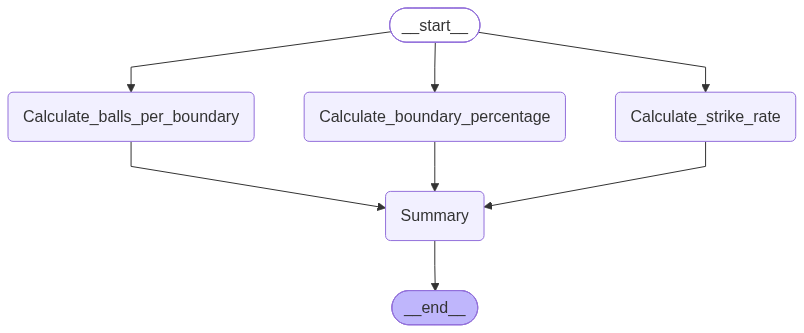

In [16]:
graph = StateGraph(CricketStatsState)

graph.add_node("Calculate_strike_rate",calculate_strike_rate)
graph.add_node("Calculate_balls_per_boundary",calculate_balls_per_boundary)
graph.add_node("Calculate_boundary_percentage",calculate_boundary_percentage)
graph.add_node("Summary",summary)

graph.add_edge(START, "Calculate_strike_rate")
graph.add_edge(START, "Calculate_balls_per_boundary")
graph.add_edge(START, "Calculate_boundary_percentage")
graph.add_edge("Calculate_strike_rate", "Summary")
graph.add_edge("Calculate_balls_per_boundary", "Summary")
graph.add_edge("Calculate_boundary_percentage", "Summary")
graph.add_edge("Summary", END)

workflow = graph.compile()

workflow



In [17]:
initial_state = {
    "runs": 120,
    "balls": 80,
    "sixes": 5,
    "fours": 10
}

final_output = workflow.invoke(initial_state)
print(final_output.get("summary", "No summary generated."))

Player scored 120 runs off 80 balls, hitting 5 sixes and 10 fours. Strike Rate: 150.00, Balls per Boundary: 5.33, Boundary Percentage: 18.75%.
